Estimated beta ≈ 0.5400 /week
Estimated gamma ≈ 0.2233 /week


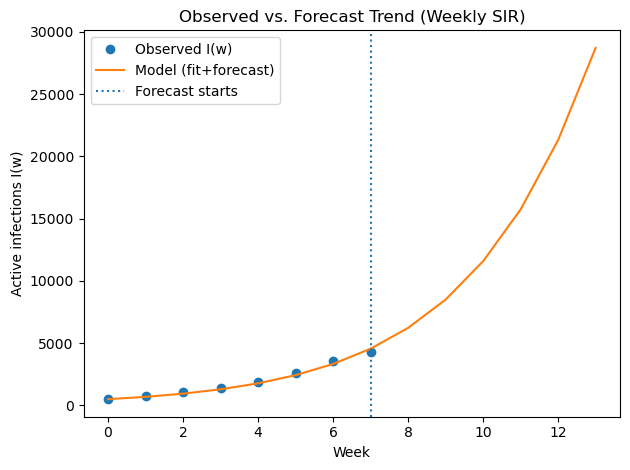

In [3]:
import numpy as np

# --- Data ---
N = 1_250_000
I0, R0 = 500, 0
S0 = N - I0 - R0
xdata = np.arange(8, dtype=float)  # weeks 0..7
I_obs = np.array([500, 740, 1050, 1400, 1910, 2600, 3550, 4300], dtype=float)

# --- SIR dynamics in weeks ---
def sir_rhs(y, beta, gamma):
    S, I, R = y
    dSdt = -beta * S * I / N
    dIdt =  beta * S * I / N - gamma * I
    dRdt =  gamma * I
    return np.array([dSdt, dIdt, dRdt], dtype=float)

# --- RK4 integrator over arbitrary time grid ---
def integrate_sir(t_grid, beta, gamma, y0, dt_max=0.05):
    # t in weeks; dt_max limits step; RK4 substeps between given points
    S, I, R = [float(y0[0])], [float(y0[1])], [float(y0[2])]
    t_prev = t_grid[0]
    y = np.array(y0, dtype=float)
    for t_next in t_grid[1:]:
        h_total = t_next - t_prev
        n_steps = max(1, int(np.ceil(abs(h_total) / dt_max)))
        h = h_total / n_steps
        for _ in range(n_steps):
            k1 = sir_rhs(y, beta, gamma)
            k2 = sir_rhs(y + 0.5*h*k1, beta, gamma)
            k3 = sir_rhs(y + 0.5*h*k2, beta, gamma)
            k4 = sir_rhs(y + h*k3, beta, gamma)
            y = y + (h/6.0)*(k1 + 2*k2 + 2*k3 + k4)
            # keep in bounds numerically
            y = np.clip(y, 0.0, N)
        S.append(y[0]); I.append(y[1]); R.append(y[2])
        t_prev = t_next
    return np.column_stack([S, I, R])

def simulate_I(t, beta, gamma):
    y0 = (S0, I0, R0)
    sol = integrate_sir(t, beta, gamma, y0)
    return sol[:, 1]  # I(t)

# --- Loss & grid search over plausible bounds ---
def mse(a, b): 
    d = a - b
    return float(np.mean(d*d))

beta_grid = np.linspace(0.10, 0.60, 51)         # per week
gamma_grid = np.linspace(1/14, 1/3, 51)         # per week

best = {"loss": np.inf, "beta": None, "gamma": None}
for beta in beta_grid:
    # early stopping hints: skip obviously explosive combos
    for gamma in gamma_grid:
        I_sim = simulate_I(xdata, beta, gamma)
        L = mse(I_sim, I_obs)
        if L < best["loss"]:
            best.update({"loss": L, "beta": beta, "gamma": gamma})

beta_hat, gamma_hat = best["beta"], best["gamma"]
print(f"Estimated beta ≈ {beta_hat:.4f} /week")
print(f"Estimated gamma ≈ {gamma_hat:.4f} /week")


# --- Visualization: observed vs fitted + forecast ---
import matplotlib.pyplot as plt

# Fitted on historical weeks
t_hist = xdata.astype(float)
I_fit_hist = simulate_I(t_hist, beta_hat, gamma_hat)

# Simple forecast H weeks ahead using same parameters
H = 6  # change if you want a longer/shorter forecast
t_all = np.arange(int(t_hist[-1]) + 1 + H, dtype=float)  # weeks 0..7+H
I_fit_all = simulate_I(t_all, beta_hat, gamma_hat)

plt.figure()
plt.plot(t_hist, I_obs, marker='o', linestyle='', label='Observed I(w)')
plt.plot(t_all, I_fit_all, linestyle='-', label='Model (fit+forecast)')
plt.axvline(x=t_hist[-1], linestyle=':', label='Forecast starts')
plt.xlabel('Week')
plt.ylabel('Active infections I(w)')
plt.title('Observed vs. Forecast Trend (Weekly SIR)')
plt.legend()
plt.tight_layout()
# plt.savefig('sir_weekly_fit_projection.png', dpi=150)  # optional
plt.show()


In [2]:
weekly_demand = 0.05 * simulate_I(np.arange(20), beta_hat, gamma_hat)
nurse_cost = 2000
penalty = 3000  # per unit of unmet FTE

candidates = np.arange(20, 200, 5)  # Try 20 to 195 nurses
best_obj, best_n = float("inf"), None

for n in candidates:
    unmet = np.maximum(weekly_demand - n, 0)
    total_penalty = np.sum(unmet) * penalty
    total_cost = n * nurse_cost * 20  # over 20 weeks
    obj = total_cost + total_penalty
    if obj < best_obj:
        best_obj, best_n = obj, n

print("Optimal nurse staffing level:", best_n)

Optimal nurse staffing level: 165
